# Algorithm Performance Comparison: Inside-Out Approach

This notebook visually benchmarks our custom "from scratch" implementations (Naive Bayes, KNN, MLP) against their highly-optimized Scikit-Learn counterparts. By importing our source code directly from the `src/` directory, we maintain a clean and modular architecture.

In [5]:
import sys
import os
sys.path.append(os.path.abspath('../src'))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from preprocessing import load_and_preprocess_titanic, scale_data
from from_scratch.naive_bayes import NaiveBayesFromScratch
from from_scratch.knn import KNNFromScratch
from from_scratch.mlp_gradient_descent import MultiLayerPerceptron

import warnings
warnings.filterwarnings('ignore')

In [6]:
X_train, X_test, y_train, y_test = load_and_preprocess_titanic()
X_train_scaled, X_test_scaled = scale_data(X_train, X_test)

--- Exploratory Data Analysis ---
Dataset Shape: (891, 15)
Missing Values:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64



In [7]:
results = {
    "Algorithm": ["Naive Bayes", "K-Nearest Neighbors", "MLP (Neural Net)"],
    "Custom": [],
    "Sklearn": []
}

# 1. Naive Bayes
nb_custom = NaiveBayesFromScratch()
nb_custom.fit(X_train_scaled, y_train)
results["Custom"].append(accuracy_score(y_test, nb_custom.predict(X_test_scaled)))

nb_sklearn = GaussianNB()
nb_sklearn.fit(X_train_scaled, y_train)
results["Sklearn"].append(accuracy_score(y_test, nb_sklearn.predict(X_test_scaled)))

# 2. KNN
knn_custom = KNNFromScratch(k=5)
knn_custom.fit(X_train_scaled, y_train)
results["Custom"].append(accuracy_score(y_test, knn_custom.predict(X_test_scaled)))

knn_sklearn = KNeighborsClassifier(n_neighbors=5)
knn_sklearn.fit(X_train_scaled, y_train)
results["Sklearn"].append(accuracy_score(y_test, knn_sklearn.predict(X_test_scaled)))

# 3. MLP (Multi-Layer Perceptron)
mlp_custom = MultiLayerPerceptron(input_dim=X_train_scaled.shape[1], hidden_dim=8, output_dim=2, epochs=500)
mlp_custom.fit(X_train_scaled, y_train)
results["Custom"].append(accuracy_score(y_test, mlp_custom.predict(X_test_scaled)))

mlp_sklearn = MLPClassifier(hidden_layer_sizes=(8,), max_iter=500, random_state=42)
mlp_sklearn.fit(X_train_scaled, y_train)
results["Sklearn"].append(accuracy_score(y_test, mlp_sklearn.predict(X_test_scaled)))

print("Evaluations completed successfully!")

Epoch    0 | Loss: 0.6931
Epoch  100 | Loss: 0.6757
Epoch  200 | Loss: 0.6692
Epoch  300 | Loss: 0.6666
Epoch  400 | Loss: 0.6654
Epoch  499 | Loss: 0.6645
Evaluations completed successfully!


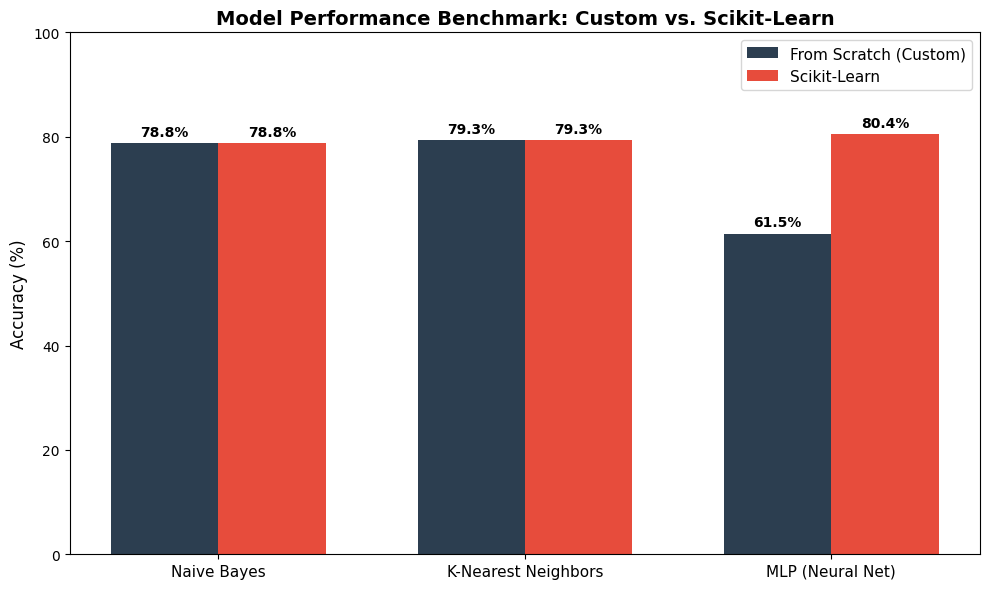

In [8]:
labels = results["Algorithm"]
custom_accs = [acc * 100 for acc in results["Custom"]]
sklearn_accs = [acc * 100 for acc in results["Sklearn"]]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, custom_accs, width, label='From Scratch (Custom)', color='#2c3e50')
rects2 = ax.bar(x + width/2, sklearn_accs, width, label='Scikit-Learn', color='#e74c3c')

ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Model Performance Benchmark: Custom vs. Scikit-Learn', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 100)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 vertical offset points
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()